# District Prosecution Profiles: K-Means Clustering

**Author:** Noor Salem · post-course rework of my clustering component

This notebook replaces the case-level clustering I submitted for the course (`notebooks/original/kmeans_clustering_v1_submitted.ipynb`).
While rebuilding the project, I found problems in v1 and in the team's cleaned dataset. This version fixes them and asks a question the data can actually answer:

> **Which federal judicial districts prosecute similar mixes of crimes, and which districts changed their mix between FY2019 and FY2025?**

| | v1 (submitted) | This notebook |
|---|---|---|
| Unit clustered | ~117k individual charge rows | District × fiscal year (one row per district per year) |
| Features | Statutory prison range, fine, duration, one-hot offense level / circuit / **sentence bucket** | Share of each district's defendants in 6 charge categories |
| Target leakage | `sentence_bucket` used as an input | None: only charge-mix shares |
| Placeholder values | `999` ("life") treated as 999 months | Not used (charge mix only) |
| Choosing k | Single seed; silhouette picked k=2 (felony vs. misdemeanor) | 10 seeds per k, WCSS + silhouette, stability check |
| Result | 2 clusters that restate offense level | 5 interpretable prosecution profiles + year-over-year shifts |

Runs on Databricks or locally with PySpark ≥ 3.5.

In [1]:
import os
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from pyspark.sql import SparkSession, functions as F, Window
from pyspark.ml.feature import VectorAssembler
from pyspark.ml.clustering import KMeans
from pyspark.ml.evaluation import ClusteringEvaluator

# On Databricks `spark` already exists; locally this starts a small session.
spark = (SparkSession.builder
         .appName("fjc-district-clustering")
         .config("spark.sql.shuffle.partitions", "8")
         .getOrCreate())
spark.sparkContext.setLogLevel("ERROR")

# Point FJC_DATA_PATH at the cleaned JSON-lines file (see data/README.md).
DATA_PATH = os.environ.get("FJC_DATA_PATH", "../data/fjc_cases_cleaned.json")
FIG_DIR, TAB_DIR = Path("../outputs/figures"), Path("../outputs/tables")
FIG_DIR.mkdir(parents=True, exist_ok=True); TAB_DIR.mkdir(parents=True, exist_ok=True)

SEED_COUNT = 10          # K-Means restarts per k
MIN_DEFENDANTS = 50      # drop district-years too small to have a stable mix
print("Spark", spark.version)

Spark 3.5.3


## 1. Load the cleaned dataset

In [2]:
raw = spark.read.json(DATA_PATH).cache()
n_rows = raw.count()
n_def = raw.select("defendant_key").distinct().count()
print(f"rows (charges): {n_rows:,}   distinct defendants: {n_def:,}   districts: {raw.select('district').distinct().count()}")
raw.groupBy("fiscal_year").count().orderBy("fiscal_year").show()

rows (charges): 117,443   distinct defendants: 65,697   districts: 94


+-----------+-----+
|fiscal_year|count|
+-----------+-----+
|       2019|59371|
|       2025|58072|
+-----------+-----+



## 2. Data audit: why v1's features were unreliable

Before clustering, I checked the columns v1 relied on. Four issues:

In [3]:
audit = raw.select(
    F.count("*").alias("rows"),
    F.sum((F.col("prison_max_months") == 999).cast("int")).alias("max_is_999_placeholder"),
    F.sum((F.col("prison_max_months") < F.col("prison_min_months")).cast("int")).alias("min_gt_max"),
    F.sum((F.col("case_duration_days") == 0).cast("int")).alias("duration_zero"),
    F.sum((F.col("case_duration_days") < 0).cast("int")).alias("duration_negative"),
).toPandas().T.rename(columns={0: "count"})
audit["pct"] = (audit["count"] / n_rows * 100).round(1)
audit

,count,pct
rows,117443,100.0
max_is_999_placeholder,34588,29.5
min_gt_max,6449,5.5
duration_zero,107231,91.3
duration_negative,785,0.7


In [4]:
# The prison columns take only a handful of values, and each value maps to exactly one sentence bucket.
# They are *statutory* ranges looked up from the offense code, not sentences a judge imposed.
raw.groupBy("prison_min_months", "prison_max_months", "sentence_bucket").count() \
   .orderBy("prison_max_months").show()

+-----------------+-----------------+---------------+-----+
|prison_min_months|prison_max_months|sentence_bucket|count|
+-----------------+-----------------+---------------+-----+
|             NULL|             NULL|           Long| 2967|
|                6|                6|          Short| 6543|
|               72|               12|         Medium| 6449|
|               12|               24|         Medium|15459|
|               24|               36|         Medium|  730|
|               36|               60|         Medium|22318|
|               60|              120|           Long| 5466|
|              120|              180|           Long| 9749|
|              180|              240|           Long|10619|
|              240|              300|           Long|  139|
|              300|              300|           Long| 2416|
|              999|              999|           Long|34588|
+-----------------+-----------------+---------------+-----+



**Findings**

1. **`999` is a placeholder for "life."** About 29% of rows have `prison_max_months = 999`. v1 averaged it as a real number, which pushed the mean "prison months" to ~350 (29 years).
2. **Inverted ranges.** 6,449 rows have `prison_min_months = 72` and `prison_max_months = 12`. That's an ETL bug, and it is why v1 had a cluster with a *negative* average sentence range.
3. **Prison columns are statutory ranges, not outcomes.** There are only 10 distinct (min, max) pairs, and `sentence_bucket` is a pure function of `prison_max_months`. Clustering or classifying on these reproduces the offense-code lookup. It says nothing about how judges actually sentenced.
4. **`case_duration_days` isn't case duration.** It is 0 for ~91% of rows and sometimes negative. It measures filing date → proceeding date.
5. **Rows are charges, not defendants.** A defendant with several charges appears several times.

So this notebook avoids the prison, fine and duration columns entirely. It uses the one thing this dataset records reliably: **what people were charged with, and where.**

## 3. Map offenses to six charge categories

An intermediate draft of this notebook tried `offense_code BETWEEN 1 AND 99 → violent`, etc. But FJC offense codes are 4-digit (100–9999), so 99.5% of rows fell into "other." Here the categories come from the U.S. Code title and the offense description instead.

In [5]:
desc = F.lower(F.col("offense_description"))
title = F.col("title_text")

charge_category = (
    F.when((title == "ALIENS AND NATIONALITY") | desc.rlike("immigration|visa|passport|nationality|alien"), "immigration")
     .when((title == "FOOD AND DRUGS") | desc.rlike("controlled substance|narcotic|marijuana|drug"), "drug")
     .when(desc.rlike("sexual|sexually explicit|failure to register"), "sex_offense")
     .when(desc.rlike("firearm|weapon|violence|violent|robbery|assault|aggravated or felonious|kidnap|carjack"
                      "|homicide|murder|manslaughter|explosive|extortion|racketeer|terrorist|threat"), "firearms_violent")
     .when(desc.rlike("fraud|launder|embezzl|tax|counterfeit|forgery|false claim|brib|theft|larceny|social security"
                      "|securities|money and finance|stolen|interstate wire|bankruptcy|lending"), "fraud_financial")
     .otherwise("public_order_other")   # traffic, trespass/curfew on federal land, escape, regulatory, etc.
)
CATS = ["immigration", "drug", "firearms_violent", "fraud_financial", "sex_offense", "public_order_other"]

df = raw.withColumn("charge_category", charge_category)
df.groupBy("charge_category").count() \
  .withColumn("pct", F.round(F.col("count") / n_rows * 100, 1)) \
  .orderBy(F.desc("count")).show()

+------------------+-----+----+
|   charge_category|count| pct|
+------------------+-----+----+
|              drug|34183|29.1|
|       immigration|31782|27.1|
|  firearms_violent|21596|18.4|
|   fraud_financial|15592|13.3|
|public_order_other| 9407| 8.0|
|       sex_offense| 4883| 4.2|
+------------------+-----+----+



In [6]:
# Sanity check: the largest offenses in the catch-all bucket should look like public-order / regulatory charges.
df.filter(F.col("charge_category") == "public_order_other") \
  .groupBy("offense_description").count().orderBy(F.desc("count")).show(12, truncate=False)

+---------------------------------------+-----+
|offense_description                    |count|
+---------------------------------------+-----+
|Traffic Offenses, Other                |2096 |
|Subversive Activities Control Act      |1518 |
|Curfew, Restricted Areas               |1427 |
|Traffic Offenses, Drunken Driving      |1161 |
|Misc. General Offenses, Other          |628  |
|Intimidation of Witnesses, Jurors, etc.|339  |
|Escape                                 |226  |
|Federal Statutes, Other                |205  |
|Escape, Aiding or Harboring            |175  |
|Maritime and Shipping Laws             |156  |
|Destroying Federal Property            |139  |
|Game Conservation Acts                 |125  |
+---------------------------------------+-----+
only showing top 12 rows



## 4. Build district × year charge-mix profiles

Each defendant counts **once**. A defendant with *n* charges contributes 1/*n* to each of their charges' categories, so every district-year's shares sum to exactly 1. District-years with fewer than 50 defendants are dropped, since their mix is too noisy.

In [7]:
per_def = Window.partitionBy("defendant_key")
weighted = df.withColumn("w", 1.0 / F.count("*").over(per_def))

profiles = (weighted.groupBy("district", "fiscal_year")
            .pivot("charge_category", CATS).agg(F.sum("w")).fillna(0.0)
            .join(weighted.groupBy("district", "fiscal_year")
                          .agg(F.countDistinct("defendant_key").alias("n_defendants")),
                  ["district", "fiscal_year"]))
for c in CATS:
    profiles = profiles.withColumn(f"pct_{c}", F.col(c) / F.col("n_defendants"))

FEATURES = [f"pct_{c}" for c in CATS]
dropped = profiles.filter(F.col("n_defendants") < MIN_DEFENDANTS).select("district", "fiscal_year", "n_defendants")
profiles = profiles.filter(F.col("n_defendants") >= MIN_DEFENDANTS).select("district", "fiscal_year", "n_defendants", *FEATURES)

# Collect the small (≈170-row) table and re-create it, so each K-Means fit below
# doesn't re-run the whole aggregation.
profiles_pd = profiles.toPandas()
print(f"district-year profiles kept: {len(profiles_pd)}   dropped (<{MIN_DEFENDANTS} defendants): {dropped.count()}")
print("shares sum to 1:", np.allclose(profiles_pd[FEATURES].sum(axis=1), 1.0))
profiles_pd.sort_values("n_defendants", ascending=False).head()

district-year profiles kept: 172   dropped (<50 defendants): 13
shares sum to 1: True


,district,fiscal_year,n_defendants,pct_immigration,pct_drug,pct_firearms_violent,pct_fraud_financial,pct_sex_offense,pct_public_order_other
7,Texas - West,2019,4055,0.762310,0.142483,0.041689,0.036523,0.009741,0.007254
130,Texas - West,2025,3808,0.695820,0.072440,0.041325,0.028633,0.010636,0.151147
6,Texas - South,2019,3550,0.787944,0.100742,0.059216,0.025291,0.013418,0.013390
69,Texas - South,2025,3042,0.741628,0.105391,0.057884,0.048362,0.016135,0.030599
97,Arizona,2025,2959,0.821370,0.079892,0.051633,0.024513,0.010899,0.011693


## 5. Choose k

The features are proportions on the same 0–1 scale, so they are **not** standardized. Standardizing would inflate rare categories like sex offenses to the same weight as immigration. Each k is fit with 10 random seeds, and the lowest-cost run is kept. That fixes v1's non-monotonic elbow, which came from a single unlucky initialization.

In [8]:
assembler = VectorAssembler(inputCols=FEATURES, outputCol="features")
X = assembler.transform(spark.createDataFrame(profiles_pd)).repartition(1).cache()
X.count()
evaluator = ClusteringEvaluator(featuresCol="features", predictionCol="cluster")  # silhouette, squared Euclidean

def best_of_seeds(k, n_seeds=SEED_COUNT):
    fits = [KMeans(k=k, seed=s, maxIter=200, featuresCol="features", predictionCol="cluster").fit(X)
            for s in range(n_seeds)]
    return min(fits, key=lambda m: m.summary.trainingCost)

rows = []
for k in range(2, 9):
    m = best_of_seeds(k)
    pred = m.transform(X)
    rows.append({"k": k, "wcss": m.summary.trainingCost, "silhouette": evaluator.evaluate(pred),
                 "smallest_cluster": min(m.summary.clusterSizes)})
k_scores = pd.DataFrame(rows)
k_scores.round(3)

,k,wcss,silhouette,smallest_cluster
0,2,7.404,0.777,13
1,3,5.860,0.398,11
2,4,4.584,0.403,11
3,5,3.491,0.478,7
4,6,2.932,0.491,7
5,7,2.657,0.412,7
6,8,2.485,0.404,6


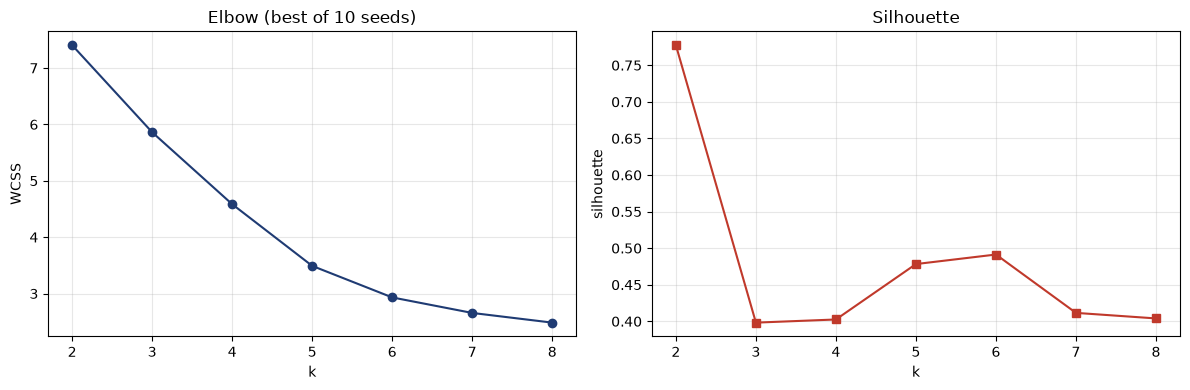

In [9]:
fig, (a1, a2) = plt.subplots(1, 2, figsize=(12, 4))
a1.plot(k_scores.k, k_scores.wcss, "o-", color="#1f3b73"); a1.set(title="Elbow (best of 10 seeds)", xlabel="k", ylabel="WCSS")
a2.plot(k_scores.k, k_scores.silhouette, "s-", color="#c0392b"); a2.set(title="Silhouette", xlabel="k", ylabel="silhouette")
for a in (a1, a2): a.grid(alpha=.3)
plt.tight_layout(); plt.savefig(FIG_DIR / "k_selection.png", dpi=150); plt.show()

In [10]:
BEST_K = 5

**Why k = 5.** Silhouette is highest at k = 2 (0.78). That split is just the handful of border districts vs. everyone else, which is real but already obvious. Among k ≥ 3, silhouette peaks at k = 6 (0.49), with k = 5 close behind (0.48). I chose k = 5 because it is simpler. Every cluster has a clear, distinct profile, while the extra cluster at k = 6 mostly splits the "mixed" group by how much immigration it has. WCSS now falls smoothly (no bump at k = 3 as in v1), because each k keeps the best of 10 seeds.

## 6. Fit the final model and check stability

In [11]:
final = best_of_seeds(BEST_K, n_seeds=20)
clustered = final.transform(X).select("district", "fiscal_year", "n_defendants", *FEATURES, "cluster").toPandas()
print("silhouette:", round(evaluator.evaluate(final.transform(X)), 3))

# Stability: how much do assignments change across single-seed runs? (Adjusted Rand Index vs. the final model)
from sklearn.metrics import adjusted_rand_score
aris = []
for s in range(100, 110):
    alt = KMeans(k=BEST_K, seed=s, maxIter=200, featuresCol="features", predictionCol="cluster").fit(X)
    alt_lab = alt.transform(X).select("district", "fiscal_year", "cluster").toPandas()
    merged = clustered.merge(alt_lab, on=["district", "fiscal_year"], suffixes=("", "_alt"))
    aris.append(adjusted_rand_score(merged.cluster, merged.cluster_alt))
print(f"ARI vs. single-seed reruns: median {np.median(aris):.2f}, min {min(aris):.2f}")

silhouette: 0.48


ARI vs. single-seed reruns: median 0.86, min 0.67


## 7. What each cluster looks like

In [12]:
overall = clustered[FEATURES].mean()
centers = clustered.groupby("cluster")[FEATURES].mean()

# Name each cluster by the category it over-represents most relative to the overall average.
NICE = {"pct_immigration": "Immigration", "pct_drug": "Drug", "pct_firearms_violent": "Firearms & violent",
        "pct_fraud_financial": "Fraud & financial", "pct_sex_offense": "Sex offense",
        "pct_public_order_other": "Public-order / federal land"}
lift = centers / overall
names = {}
for c in centers.index:
    top = lift.loc[c].idxmax()
    names[c] = f"{NICE[top]}-heavy"
# Border districts: immigration share far above everyone else
names[centers["pct_immigration"].idxmax()] = "Border immigration"
# Mixed: the cluster whose profile is closest to the national average
names[((centers - overall) ** 2).sum(axis=1).idxmin()] = "Mixed / national average"
clustered["profile"] = clustered.cluster.map(names)

summary = (centers.rename(columns=NICE).mul(100).round(1)
           .assign(district_years=clustered.groupby("cluster").size())
           .rename(index=names))
summary

,Immigration,Drug,Firearms & violent,Fraud & financial,Sex offense,Public-order / federal land,district_years
cluster,,,,,,,
Drug-heavy,9.6,42.0,22.6,14.5,6.6,4.7,61
Public-order / federal land-heavy,8.7,19.0,13.1,13.4,3.2,42.6,7
Firearms & violent-heavy,8.5,27.3,39.6,13.4,6.6,4.6,47
Mixed / national average,22.9,25.1,21.2,19.8,6.7,4.2,46
Border immigration,69.7,15.2,4.9,4.6,0.9,4.7,11


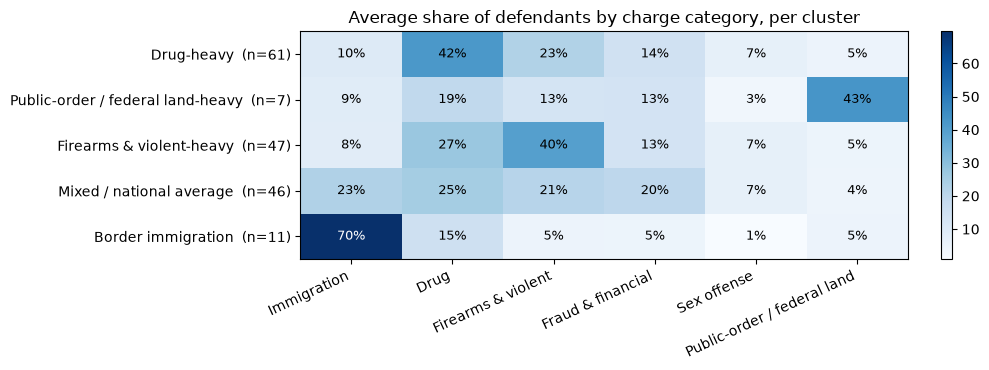

In [13]:
fig, ax = plt.subplots(figsize=(10, 3.8))
mat = summary.drop(columns="district_years")
im = ax.imshow(mat.values, cmap="Blues", aspect="auto")
ax.set_xticks(range(mat.shape[1]), mat.columns, rotation=25, ha="right")
ax.set_yticks(range(mat.shape[0]), [f"{i}  (n={n})" for i, n in zip(mat.index, summary.district_years)])
for i in range(mat.shape[0]):
    for j in range(mat.shape[1]):
        v = mat.values[i, j]
        ax.text(j, i, f"{v:.0f}%", ha="center", va="center", color="white" if v > 45 else "black", fontsize=9)
ax.set_title("Average share of defendants by charge category, per cluster")
plt.colorbar(im, ax=ax, fraction=.025); plt.tight_layout()
plt.savefig(FIG_DIR / "cluster_profiles_heatmap.png", dpi=150); plt.show()

In [14]:
for p, g in clustered.groupby("profile"):
    ds = sorted(set(g.district))
    print(f"{p} ({len(ds)} districts): " + ", ".join(ds[:12]) + (" …" if len(ds) > 12 else ""))

Border immigration (6 districts): Arizona, California - South, District Court of the Virgin Islands, New Mexico, Texas - South, Texas - West
Drug-heavy (47 districts): Alaska, Arkansas - East, Arkansas - West, California - Central, California - East, California - North, Colorado, Connecticut, Georgia - Middle, Georgia - North, Georgia - South, Hawaii …
Firearms & violent-heavy (32 districts): Alabama - Middle, Alabama - North, Alabama - South, Alaska, Arkansas - East, Colorado, District of Columbia, Georgia - South, Illinois - North, Illinois - South, Indiana - North, Indiana - South …
Mixed / national average (33 districts): Alabama - South, California - Central, Delaware, District Court of the Virgin Islands, Florida - Middle, Florida - North, Florida - South, Georgia - North, Idaho, Louisiana - East, Louisiana - Middle, Massachusetts …
Public-order / federal land-heavy (5 districts): Maryland, New York - East, North Carolina - East, Virginia - East, Washington - West


## 8. Which districts changed profile between FY2019 and FY2025?

In [15]:
wide = clustered.pivot(index="district", columns="fiscal_year", values="profile").dropna()
wide.columns = ["fy2019", "fy2025"]
movers = wide[wide.fy2019 != wide.fy2025]
print(f"{len(wide)} districts have enough cases in both years; {len(movers)} changed profile.")
pd.crosstab(wide.fy2019, wide.fy2025, rownames=["FY2019 →"], colnames=["FY2025"])

81 districts have enough cases in both years; 32 changed profile.


FY2025,Border immigration,Drug-heavy,Firearms & violent-heavy,Mixed / national average,Public-order / federal land-heavy
FY2019 →,,,,,
Border immigration,5,0,0,0,0
Drug-heavy,0,14,7,11,1
Firearms & violent-heavy,0,6,15,2,0
Mixed / national average,1,2,0,13,0
Public-order / federal land-heavy,0,1,0,1,2


In [16]:
imm = clustered.pivot(index="district", columns="fiscal_year", values="pct_immigration")
movers = movers.assign(immigration_2019=(imm.loc[movers.index, 2019] * 100).round(1),
                       immigration_2025=(imm.loc[movers.index, 2025] * 100).round(1))
movers = movers.assign(change_pts=movers.immigration_2025 - movers.immigration_2019).sort_values("change_pts", ascending=False)
movers

,fy2019,fy2025,immigration_2019,immigration_2025,change_pts
district,,,,,
District Court of the Virgin Islands,Mixed / national average,Border immigration,18.3,48.5,30.2
Minnesota,Drug-heavy,Mixed / national average,6.3,27.6,21.3
Georgia - North,Drug-heavy,Mixed / national average,11.7,31.3,19.6
New York - East,Public-order / federal land-heavy,Mixed / national average,21.6,38.6,17.0
Vermont,Drug-heavy,Mixed / national average,7.6,21.3,13.7
Oklahoma - North,Firearms & violent-heavy,Mixed / national average,9.3,22.3,13.0
California - Central,Drug-heavy,Mixed / national average,6.7,19.2,12.5
Michigan - West,Drug-heavy,Mixed / national average,12.8,24.5,11.7
Texas - North,Drug-heavy,Mixed / national average,13.1,24.1,11.0


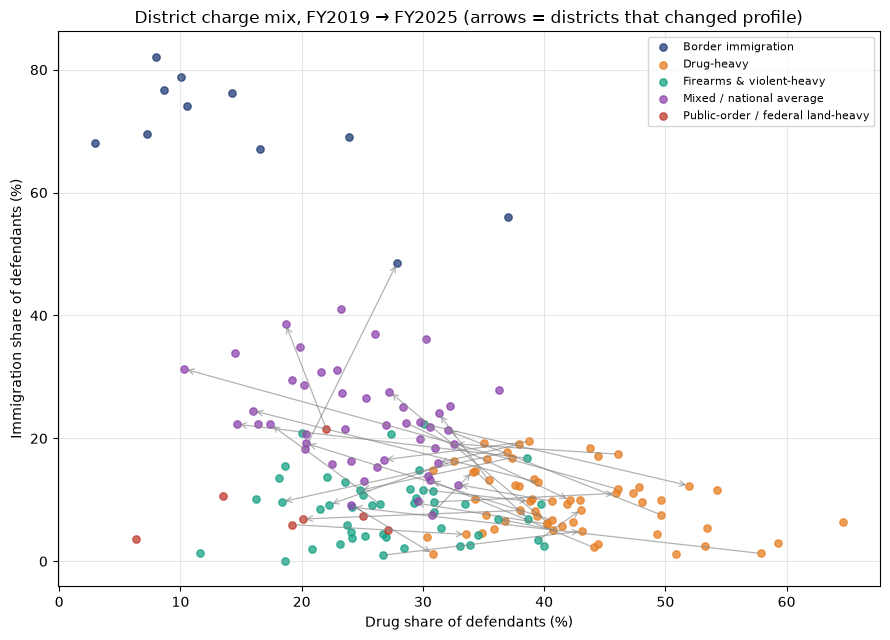

In [17]:
fig, ax = plt.subplots(figsize=(9, 6.5))
palette = dict(zip(sorted(clustered.profile.unique()), ["#1f3b73", "#e67e22", "#16a085", "#8e44ad", "#c0392b"]))
for prof, g in clustered.groupby("profile"):
    ax.scatter(g.pct_drug * 100, g.pct_immigration * 100, s=28, alpha=.75, color=palette[prof], label=prof)
piv = clustered.set_index(["district", "fiscal_year"])
for d in movers.index:
    a, b = piv.loc[(d, 2019)], piv.loc[(d, 2025)]
    ax.annotate("", xy=(b.pct_drug * 100, b.pct_immigration * 100), xytext=(a.pct_drug * 100, a.pct_immigration * 100),
                arrowprops=dict(arrowstyle="->", color="grey", alpha=.6, lw=.9))
ax.set(xlabel="Drug share of defendants (%)", ylabel="Immigration share of defendants (%)",
       title="District charge mix, FY2019 → FY2025 (arrows = districts that changed profile)")
ax.legend(fontsize=8, loc="upper right"); ax.grid(alpha=.3); plt.tight_layout()
plt.savefig(FIG_DIR / "district_shifts_2019_2025.png", dpi=150); plt.show()

**Reading the shifts**

- **Border districts are stable.** All five border districts with data in both years stay *Border immigration*.
- **Immigration spread inland.** The biggest single movement is *Drug-heavy → Mixed* (11 districts). The top movers are interior districts whose immigration share jumped. Examples: Minnesota (6% → 28%), Georgia-North (12% → 31%), Vermont (8% → 21%), Central California (7% → 19%), Southern Ohio (2% → 13%). Across the 81 districts with data in both years, the median immigration share rose from 9.9% to 12.4%, and 48 districts increased.
- **Not every move is about immigration.** A second group moved between *Drug-heavy* and *Firearms & violent-heavy* in both directions. That reflects shifting drug vs. gun enforcement, not immigration.

## 9. Save results

In [18]:
clustered.drop(columns="cluster").sort_values(["district", "fiscal_year"]) \
         .to_csv(TAB_DIR / "district_cluster_assignments.csv", index=False)
summary.to_csv(TAB_DIR / "cluster_profiles.csv")
movers.to_csv(TAB_DIR / "district_profile_changes_2019_2025.csv")
k_scores.to_csv(TAB_DIR / "k_selection.csv", index=False)
print("saved to", TAB_DIR)

saved to ../outputs/tables


## Limitations

- **Charges, not convictions.** The dataset records what was filed. Most FY2025 cases were still pending when the data was pulled.
- **Keyword-based categories.** The mapping from offense description to category is rule-based and readable, but a few offenses are ambiguous (e.g., "Racketeering" goes to firearms & violent).
- **Two snapshots.** FY2019 vs. FY2025 shows *that* a district's mix changed, not when or why. Including 2020–2024 would allow a proper trajectory analysis.
- **National-defense trespass charges.** In FY2025, border districts filed many "security regulation / military property" charges alongside illegal entry. They land in *public-order* here. Folding them into immigration would make the border shift even sharper.